# **PROJETO II – Classificação de imagens utilizando Machine Learning**

**Objetivo:** desenvolver e avaliar modelos de classificação de rostos utilizando o conjunto de dados *Labelled Faces in the Wild (LFW)*.

Neste projeto, serão realizadas a exploração dos dados, a visualização de imagens, a preparação dos dados, a separação entre treino e teste e a comparação de classificadores. Ao final, serão analisadas métricas como acurácia, precisão, revocação (*recall*) e F1-score.

## 1. Dataset

O *Labelled Faces in the Wild (LFW)* é um conjunto de imagens de rostos identificados por pessoa. Cada imagem será representada numericamente para que os algoritmos de *Machine Learning* possam processá-la.

O código abaixo carrega pessoas com pelo menos 10 imagens. **Observação:** o enunciado também solicita acrescentar fotos da turma. Essas imagens não estão incluídas no notebook recebido; para cumprir essa parte, será necessário adicioná-las ao conjunto de dados seguindo o mesmo padrão de organização e identificação.

## 2. Bibliotecas

Importamos as bibliotecas para manipulação dos dados, visualização, divisão dos conjuntos e treinamento dos classificadores.

In [1]:
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

## 3. Importação e informações do dataset

O parâmetro `min_faces_per_person=10` seleciona pessoas que possuem pelo menos 10 imagens. `X` contém os pixels de cada imagem em formato vetorial, enquanto `y` contém o identificador numérico da pessoa.

In [2]:
lfw_dataset = fetch_lfw_people(min_faces_per_person=10, resize=0.5)

images = lfw_dataset.images
X = lfw_dataset.data
y = lfw_dataset.target
target_names = lfw_dataset.target_names
tamanho_imagem = images.shape[1:]

print(f"Quantidade de imagens: {X.shape[0]}")
print(f"Dimensões de cada imagem: {tamanho_imagem}")
print(f"Quantidade de pessoas/classes: {len(target_names)}")
print(f"Quantidade de pixels por imagem: {X.shape[1]}")

Quantidade de imagens: 4324
Dimensões de cada imagem: (62, 47)
Quantidade de pessoas/classes: 158
Quantidade de pixels por imagem: 2914


## 4. Análise exploratória

### 4.1 Quantidade de imagens por pessoa

Esta análise permite observar como as imagens estão distribuídas entre as classes. A quantidade de imagens não é necessariamente igual para todas as pessoas.

,Pessoa,Quantidade de imagens
35,George W Bush,530
23,Colin Powell,236
149,Tony Blair,144
29,Donald Rumsfeld,121
36,Gerhard Schroeder,109
11,Ariel Sharon,77
49,Hugo Chavez,71
85,Junichiro Koizumi,60
61,Jean Chretien,55
73,John Ashcroft,53


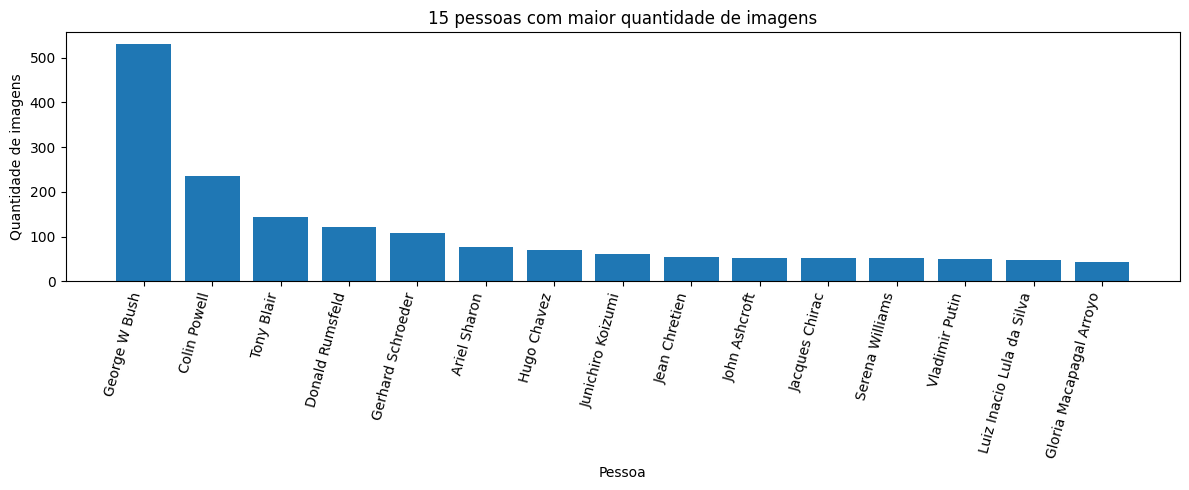

In [3]:
contagem_classes = pd.Series(y).value_counts().sort_index()
distribuicao = pd.DataFrame({
    "Pessoa": target_names,
    "Quantidade de imagens": [int(contagem_classes.get(i, 0)) for i in range(len(target_names))]
}).sort_values("Quantidade de imagens", ascending=False)

display(distribuicao.head(15))

plt.figure(figsize=(12, 5))
plt.bar(distribuicao["Pessoa"].head(15), distribuicao["Quantidade de imagens"].head(15))
plt.title("15 pessoas com maior quantidade de imagens")
plt.xlabel("Pessoa")
plt.ylabel("Quantidade de imagens")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

### 4.2 Visualização de uma imagem

As imagens são apresentadas em tons de cinza, pois o dataset fornece os rostos nesse formato.

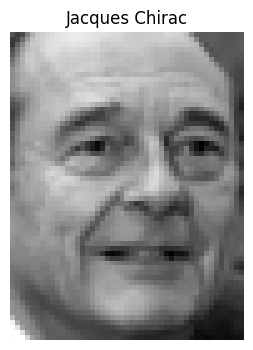

In [4]:
plt.figure(figsize=(4, 4))
plt.imshow(images[0], cmap="gray")
plt.title(target_names[y[0]])
plt.axis("off")
plt.show()

### 4.3 Amostra de 15 imagens aleatórias

A visualização de várias imagens ajuda a conferir os dados e a identificar a variedade de rostos presente no conjunto.

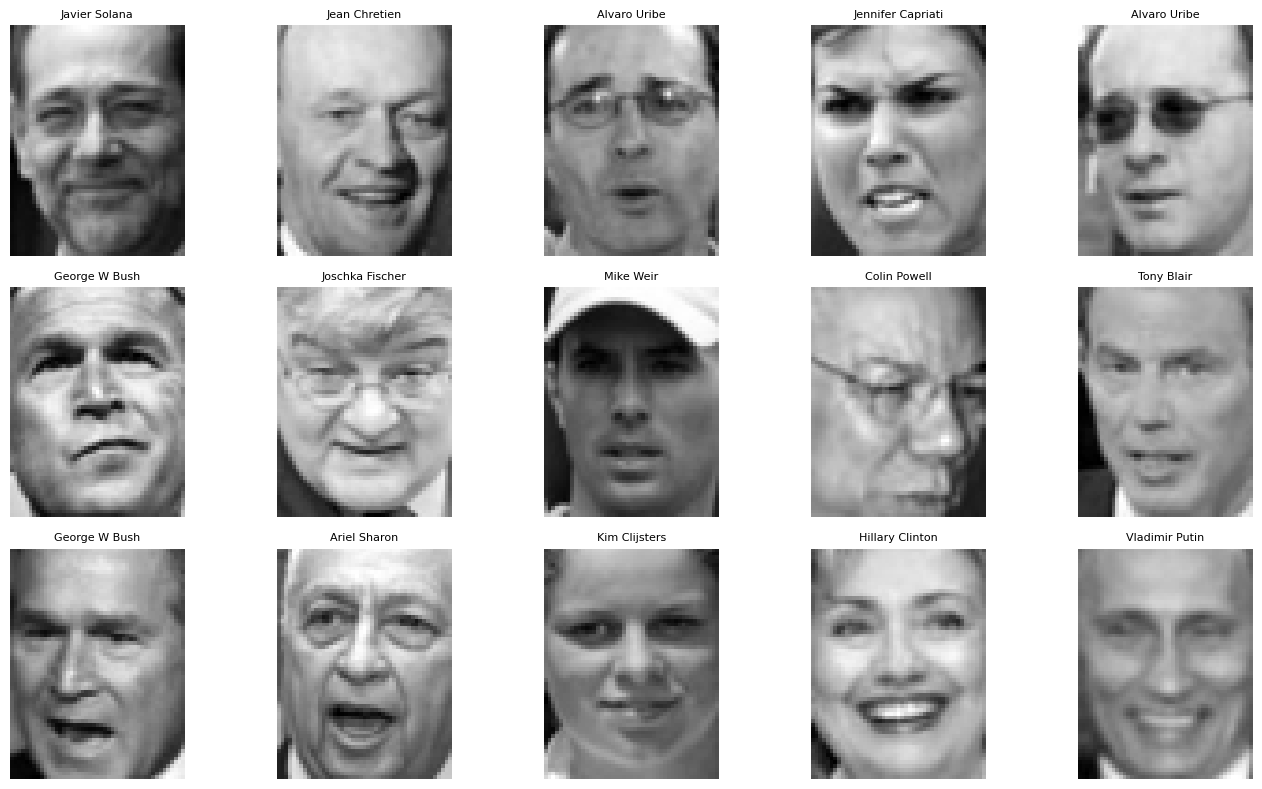

In [5]:
random.seed(42)
num_figures = min(15, len(X))
random_indices = random.sample(range(len(X)), num_figures)

fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for ax, idx in zip(axes.flatten(), random_indices):
    ax.imshow(images[idx], cmap="gray")
    ax.set_title(target_names[y[idx]], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Preparação dos dados

Cada imagem já está representada por valores numéricos de pixels. O carregador do LFW retorna os pixels em escala de cinza e normalizados aproximadamente entre 0 e 1. Portanto, não é necessário aplicar uma nova divisão por 255.

Vamos separar 70% das imagens para treinamento e 30% para teste. O parâmetro `stratify=y` tenta manter a proporção das classes nos dois conjuntos. A divisão é feita antes do treinamento para avaliar os modelos em imagens que não foram usadas para ajustá-los.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Imagens para treinamento:", X_train.shape[0])
print("Imagens para teste:", X_test.shape[0])
print("Classes no treinamento:", len(np.unique(y_train)))
print("Classes no teste:", len(np.unique(y_test)))

Imagens para treinamento: 3026
Imagens para teste: 1298
Classes no treinamento: 158
Classes no teste: 158


## 6. Treinamento e comparação dos classificadores

Serão comparados três algoritmos:

- **SVM:** procura uma separação entre as classes e costuma ser utilizado em tarefas de reconhecimento facial.
- **K-NN:** classifica uma imagem considerando as classes das imagens mais próximas.
- **Random Forest:** combina várias árvores de decisão para realizar a classificação.

No SVM e no K-NN, usamos `StandardScaler` dentro de um *pipeline*. Assim, o escalonador é ajustado somente com os dados de treinamento, evitando vazamento de informações do conjunto de teste. Para o Random Forest, mantemos os valores originais dos pixels normalizados.

In [7]:
modelos = {
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    ),
    "K-NN (5 vizinhos)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample"
    )
}

resultados = []
modelos_treinados = {}

for nome, modelo in modelos.items():
    print(f"Treinando: {nome}")
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    modelos_treinados[nome] = modelo

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

tabela_resultados = pd.DataFrame(resultados).sort_values("F1-score (macro)", ascending=False)
display(tabela_resultados.round(4))

Treinando: SVM (RBF)
Treinando: K-NN (5 vizinhos)
Treinando: Random Forest


,Modelo,Acurácia,Precisão (macro),Recall (macro),F1-score (macro)
0,SVM (RBF),0.2843,0.2893,0.2611,0.2463
2,Random Forest,0.2589,0.1929,0.1318,0.1352
1,K-NN (5 vizinhos),0.2257,0.1703,0.1045,0.1080


## 7. Comparação visual das métricas

A acurácia mostra a proporção total de previsões corretas. Precisão, *recall* e F1-score são calculados pela média macro, dando o mesmo peso a cada pessoa/classe. Isso ajuda na análise quando há quantidades diferentes de imagens por pessoa.

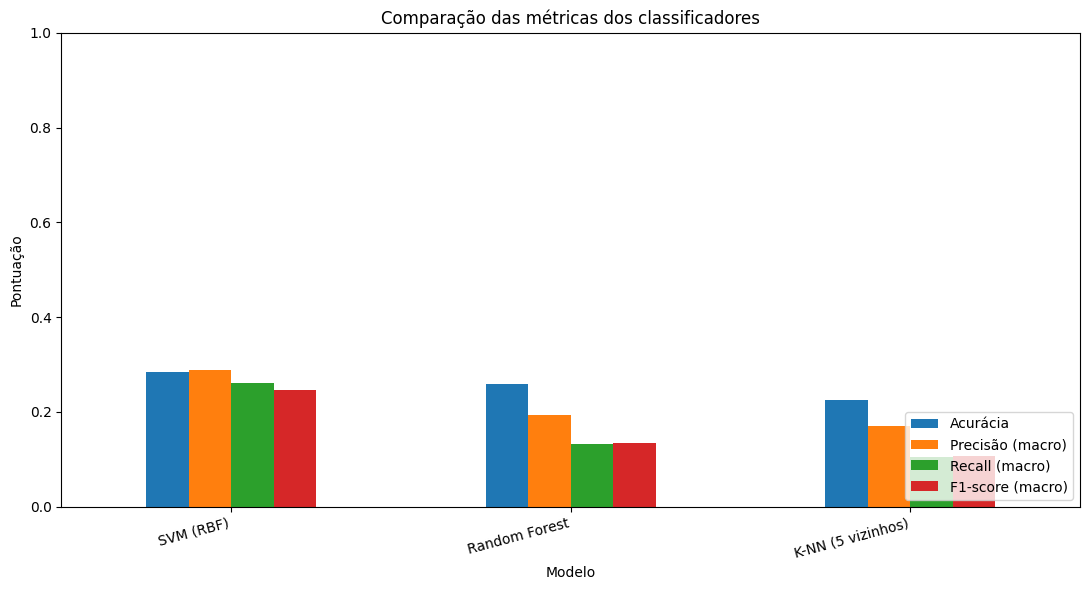

In [8]:
metricas = ["Acurácia", "Precisão (macro)", "Recall (macro)", "F1-score (macro)"]
tabela_resultados.set_index("Modelo")[metricas].plot(kind="bar", figsize=(11, 6))
plt.title("Comparação das métricas dos classificadores")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Avaliação detalhada do melhor modelo

Selecionamos o modelo com maior F1-score macro na tabela de resultados. O relatório apresenta precisão, *recall* e F1-score por classe. Como o dataset pode conter muitas pessoas, a matriz de confusão completa pode ficar grande; por isso, exibimos a matriz normalizada para as classes mais frequentes no conjunto de teste.

In [9]:
melhor_nome = tabela_resultados.iloc[0]["Modelo"]
melhor_modelo = modelos_treinados[melhor_nome]
y_pred_melhor = melhor_modelo.predict(X_test)

print("Melhor modelo pelo F1-score macro:", melhor_nome)
print("\nRelatório de classificação:")
print(classification_report(
    y_test, y_pred_melhor,
    labels=np.arange(len(target_names)),
    target_names=target_names,
    zero_division=0
))

Melhor modelo pelo F1-score macro: SVM (RBF)

Relatório de classificação:
                           precision    recall  f1-score   support

             Abdullah Gul       1.00      0.67      0.80         6
             Adrien Brody       0.33      0.25      0.29         4
         Alejandro Toledo       0.10      0.17      0.12        12
             Alvaro Uribe       0.40      0.18      0.25        11
          Amelie Mauresmo       0.20      0.50      0.29         6
             Andre Agassi       0.18      0.55      0.27        11
             Andy Roddick       0.33      0.25      0.29         4
           Angelina Jolie       0.17      0.17      0.17         6
              Ann Veneman       0.50      0.33      0.40         3
          Anna Kournikova       0.00      0.00      0.00         4
            Ari Fleischer       0.00      0.00      0.00         4
             Ariel Sharon       0.22      0.22      0.22        23
    Arnold Schwarzenegger       0.10      0.23      0.

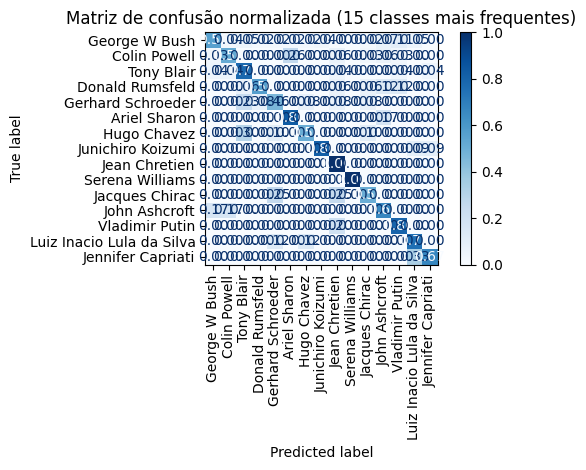

In [10]:
# Seleciona até 15 classes mais frequentes no conjunto de teste
classes_frequentes = pd.Series(y_test).value_counts().head(15).index.to_numpy()
mascara = np.isin(y_test, classes_frequentes)
y_test_filtrado = y_test[mascara]
y_pred_filtrado = y_pred_melhor[mascara]

ConfusionMatrixDisplay.from_predictions(
    y_test_filtrado,
    y_pred_filtrado,
    labels=classes_frequentes,
    display_labels=target_names[classes_frequentes],
    normalize="true",
    xticks_rotation=90,
    cmap="Blues",
    values_format=".2f"
)
plt.title("Matriz de confusão normalizada (15 classes mais frequentes)")
plt.tight_layout()
plt.show()

## 9. Testando a previsão de uma imagem

A célula abaixo seleciona uma imagem do conjunto de teste, mostra o nome real e o nome previsto pelo melhor modelo. Isso permite observar um exemplo individual de classificação.

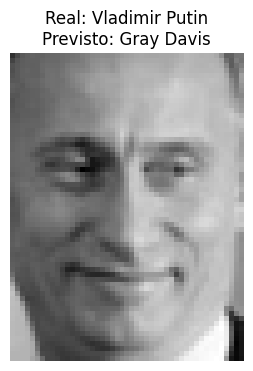

Classe real: Vladimir Putin
Classe prevista: Gray Davis
Resultado: Errou


In [11]:
indice = 0
imagem_teste = X_test[indice].reshape(1, -1)
classe_real = target_names[y_test[indice]]
classe_prevista_id = melhor_modelo.predict(imagem_teste)[0]
classe_prevista = target_names[classe_prevista_id]

plt.figure(figsize=(4, 4))
plt.imshow(X_test[indice].reshape(tamanho_imagem), cmap="gray")
plt.title(f"Real: {classe_real}\nPrevisto: {classe_prevista}")
plt.axis("off")
plt.show()

print("Classe real:", classe_real)
print("Classe prevista:", classe_prevista)
print("Resultado:", "Acertou" if classe_real == classe_prevista else "Errou")

## 10. Conclusão

Após executar todas as células, compare os resultados apresentados na tabela e nos gráficos. O modelo com maior F1-score macro foi selecionado para a avaliação detalhada. A acurácia, a precisão, o *recall* e o F1-score devem ser considerados em conjunto, pois cada métrica mostra um aspecto diferente do desempenho.

O desempenho obtido depende das imagens utilizadas, da distribuição das pessoas entre as classes e dos parâmetros escolhidos. Por isso, os valores finais devem ser registrados a partir da execução do notebook, sem estimar resultados antecipadamente.

**Observação sobre o enunciado:** o arquivo recebido solicita incluir fotos da turma no dataset. Como essas fotos não foram fornecidas junto com o notebook, essa etapa precisa ser realizada separadamente para que a base final também contenha as imagens solicitadas.